In [5]:
%matplotlib inline
import sys
import h5py
import numpy as np
import torch
from torch.utils.data import ConcatDataset, DataLoader
import matplotlib.pyplot as plt
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
from matplotlib.ticker import LogLocator
from sklearn.metrics import roc_curve, auc

sys.path.append("/data/condor_shared/users/nmanic/RNO_machine_learning/RNO_classifier/classifier_consistency/train_eval")

from train_benchmark import ARCH_REGISTRY, WaveformDataset
from evaluate_comparison import get_scores, threshold_at_fpr

ckpt_path = "/data/i3store/users/nmanic/classifier_consistency/ARZ2020/benchmark/runs/exp01/best_model.pt"

# Variables for choosing plotting data
signal_path = "/data/i3store/users/nmanic/classifier_consistency/ARZ2020/benchmark/nu/nu_extracted.hdf5"
noise_path = "/data/i3store/users/nmanic/classifier_consistency/ARZ2020/benchmark/noise/noise_extracted.hdf5"
target_fpr = 1e-3
# Set compare to True if signal & noise files aren't what the model was trained on
compare = False
batch_size = 512

device = (torch.device("cuda") if torch.cuda.is_available() else
              torch.device("mps")  if torch.backends.mps.is_available() else
              torch.device("cpu"))

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
cfg  = ckpt.get("config", {})

model = ARCH_REGISTRY[cfg.get("arch", "baseline")](n_channels=4).to(device)
model.load_state_dict(ckpt["model_state"])

if "sig_val_idx" not in ckpt or "noi_val_idx" not in ckpt:
        sys.exit(
            "ERROR: checkpoint does not contain val indices.\n"
            "Re-run step2_train.py to produce a new checkpoint, then evaluate again."
        )
sig_val_idx = ckpt["sig_val_idx"]
noi_val_idx = ckpt["noi_val_idx"]

if compare:
    with h5py.File(signal_path, "r") as f:
        sig_val_idx = np.arange(f["waveforms"].shape[0])
    with h5py.File(noise_path,  "r") as f:
        noi_val_idx = np.arange(f["waveforms"].shape[0])
    print(f"Comparison mode: using all {len(sig_val_idx)} signal "
        f"and {len(noi_val_idx)} noise events")

crop = cfg.get("crop_samples", None)
val_ds = ConcatDataset([
    WaveformDataset(signal_path, sig_val_idx, crop),
    WaveformDataset(noise_path,  noi_val_idx, crop),
])
loader = DataLoader(val_ds, batch_size=batch_size,
                    shuffle=False, num_workers=4, persistent_workers=True,
                    pin_memory=(device.type == "cuda"))

# ── inference ─────────────────────────────────────────────────────────────
scores, val_labels = get_scores(model, loader, device)

# ── ROC + threshold ───────────────────────────────────────────────────────
fpr_arr, tpr_arr, thresholds = roc_curve(val_labels, scores, pos_label=1)
roc_auc = auc(fpr_arr, tpr_arr)
threshold, op_fpr, op_tpr = threshold_at_fpr(
    fpr_arr, tpr_arr, thresholds, target_fpr)

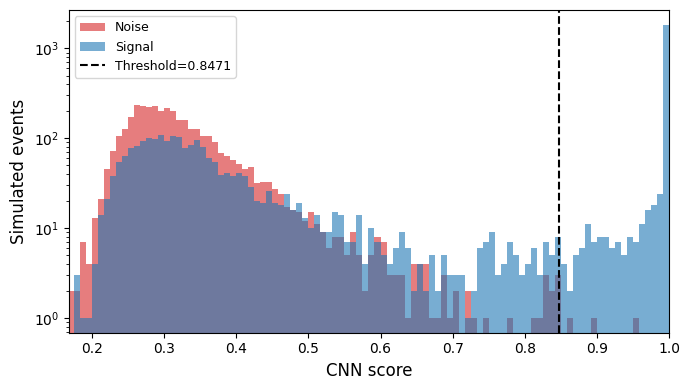

In [8]:
n_bins = 120

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(scores[val_labels == 0], bins=n_bins, range=(0, 1),
        alpha=0.6, color="tab:red",  label="Noise")
ax.hist(scores[val_labels == 1], bins=n_bins, range=(0, 1),
        alpha=0.6, color="tab:blue", label="Signal")
ax.axvline(threshold, ls="--", color="black", label=f"Threshold={threshold:.4f}")
ax.set_xlabel("CNN score", fontsize=12) 
ax.set_ylabel("Simulated events", fontsize=12)
ax.legend(loc="upper left",fontsize=9)
ax.set_yscale("log")
ax.set_xlim(min(scores), max(scores))

#ax.grid(True, alpha=0.5)

fig.tight_layout()
plt.show()